# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Nur Ihsan
- **Email:** nurihsanazhari@gmail.com
- **ID Dicoding:** nurihsannn

## Menentukan Pertanyaan Bisnis

- **Pertanyaan 1 (Konsentrasi Kota):** Di 10 kota (city) manakah konsentrasi pelanggan terbesar berada berdasarkan jumlah pelanggan unik dan persentase kontribusinya selama periode 2016-2018, sehingga tim logistik dapat memprioritaskan pembangunan pusat distribusi (hub) di kota-kota tersebut pada kuartal depan?
  - *Specific*: Fokus pada 10 kota dengan pelanggan terbanyak.
  - *Measurable*: Dihitung berdasarkan jumlah pelanggan unik dan persentase kontribusinya terhadap total pelanggan.
  - *Action-Oriented*: Hasilnya digunakan untuk menentukan prioritas lokasi pembangunan gudang/hub distribusi logistik.
  - *Relevant*: Mempercepat waktu pengiriman e-commerce.
  - *Time-bound*: Menggunakan data periode 2016-2018 untuk perencanaan kuartal depan.

- **Pertanyaan 2 (Konsentrasi Negara Bagian):** Bagaimana perbandingan distribusi pelanggan (jumlah dan persentase) di 5 negara bagian (state) teratas selama periode 2016-2018, agar tim marketing dapat mengalokasikan budget promosi secara proporsional berdasarkan ukuran pasar tiap wilayah pada tahun ini?
  - *Specific*: Fokus pada 5 negara bagian (state) teratas.
  - *Measurable*: Dihitung menggunakan metrik jumlah pelanggan unik dan persentasenya.
  - *Action-Oriented*: Tim marketing dapat membagi persentase budget ads sesuai ukuran pasar tiap state.
  - *Relevant*: Relevan untuk efisiensi Customer Acquisition Cost (CAC).
  - *Time-bound*: Menggunakan data 2016-2018 untuk alokasi budget tahun ini.

## Import Semua Packages/Library yang Digunakan

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

In [2]:
customers_df = pd.read_csv("olist_customers_dataset.csv")

display(customers_df.head())

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


### Assessing Data

In [3]:
print("--- Info Dataset ---")
customers_df.info()
print("\n--- Missing Values ---")
print(customers_df.isna().sum())

print(f"\nJumlah duplikasi data persis: {customers_df.duplicated().sum()}")

duplikasi_id = customers_df['customer_unique_id'].duplicated().sum()
print(f"Jumlah pelanggan yang melakukan repeat order (duplikat ID): {duplikasi_id}")

--- Info Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB

--- Missing Values ---
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

Jumlah duplikasi data persis: 0
Jumlah pelanggan yang melakukan repeat order (duplikat ID): 3345


**Insight & Identifying Problem:**
- **Missing Value & Invalid Value:** Data pelanggan terlihat sangat bersih, tidak ada *missing value* pada kolom manapun dan tipe data sudah sesuai (object/string).
- **Duplicate Data:** Tidak ditemukan baris yang duplikat secara identik di semua kolom. Namun, ditemukan bahwa satu pelanggan fisik (direpresentasikan oleh `customer_unique_id`) muncul berkali-kali jika mereka melakukan beberapa transaksi (*repeat order*).
- **Steps to Take:** Karena tujuan analisis kita adalah memetakan demografi "pelanggan" (bukan transaksi), kita harus menghapus duplikasi pada kolom `customer_unique_id` di tahap Cleaning Data agar data tidak bias.

### Cleaning Data

In [4]:
print(f"Total baris sebelum dibersihkan: {customers_df.shape[0]}")

customers_df.drop_duplicates(subset=['customer_unique_id'], keep='first', inplace=True)

print(f"Total baris sesudah dibersihkan: {customers_df.shape[0]}")
print(f"Sisa duplikasi customer_unique_id: {customers_df['customer_unique_id'].duplicated().sum()}")

Total baris sebelum dibersihkan: 99441
Total baris sesudah dibersihkan: 96096
Sisa duplikasi customer_unique_id: 0


**Insight Setelah Pembersihan:**
- Sekitar lebih dari 3.000 data pelanggan yang berulang (*repeat orders*) berhasil dihapus. Dataset kini sudah 100% merepresentasikan populasi unik pelanggan, sehingga analisis spasial (kota dan negara bagian) menjadi jauh lebih akurat.

## Exploratory Data Analysis (EDA)

In [5]:
# Menghitung total pelanggan unik keseluruhan
total_customers = customers_df['customer_unique_id'].nunique()

# Eksplorasi 1: Menghitung jumlah dan persentase pelanggan per kota
top_cities = customers_df.groupby('customer_city').customer_unique_id.nunique().sort_values(ascending=False).reset_index()
top_cities.rename(columns={'customer_unique_id': 'customer_count'}, inplace=True)
top_cities['percentage (%)'] = round((top_cities['customer_count'] / total_customers) * 100, 2)

# Eksplorasi 2: Menghitung jumlah dan persentase pelanggan per Negara Bagian
top_states = customers_df.groupby('customer_state').customer_unique_id.nunique().sort_values(ascending=False).reset_index()
top_states.rename(columns={'customer_unique_id': 'customer_count'}, inplace=True)
top_states['percentage (%)'] = round((top_states['customer_count'] / total_customers) * 100, 2)

print("--- Top 10 Kota ---")
display(top_cities.head(10))

print("\n--- Top 5 Negara Bagian ---")
display(top_states.head(5))

--- Top 10 Kota ---


,customer_city,customer_count,percentage (%)
0,sao paulo,14971,15.58
1,rio de janeiro,6611,6.88
2,belo horizonte,2671,2.78
3,brasilia,2066,2.15
4,curitiba,1462,1.52
5,campinas,1397,1.45
6,porto alegre,1326,1.38
7,salvador,1208,1.26
8,guarulhos,1151,1.20
9,sao bernardo do campo,908,0.94



--- Top 5 Negara Bagian ---


,customer_state,customer_count,percentage (%)
0,SP,40295,41.93
1,RJ,12377,12.88
2,MG,11255,11.71
3,RS,5277,5.49
4,PR,4882,5.08


## Visualization & Explanatory Analysis

### Pertanyaan 1: Di 10 kota (city) manakah konsentrasi pelanggan terbesar berada?

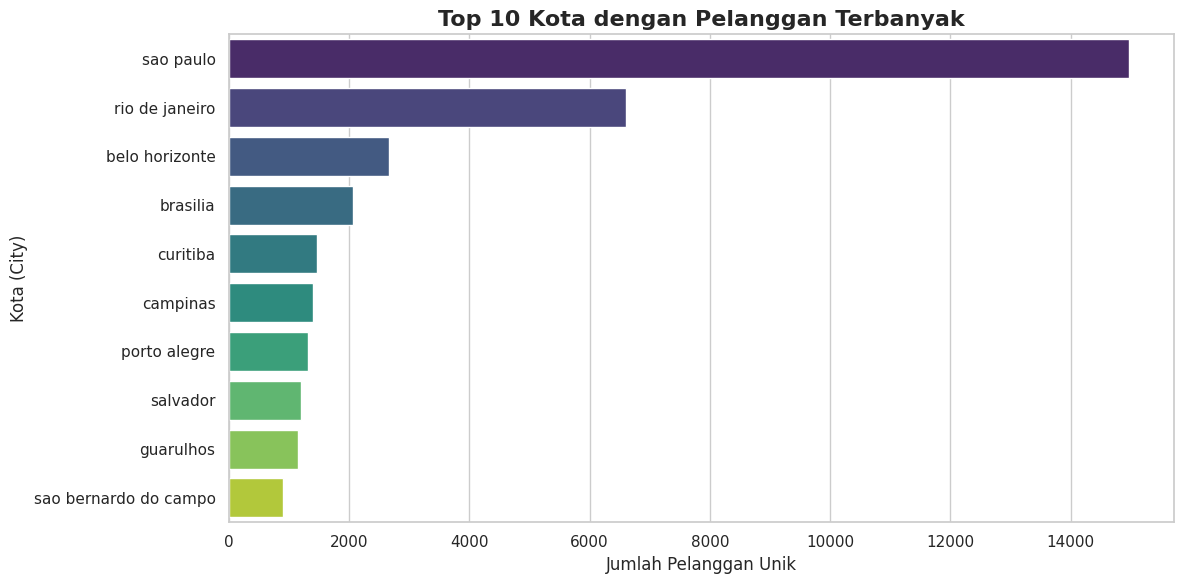

In [6]:
plt.figure(figsize=(12, 6))
sns.barplot(
    x='customer_count',
    y='customer_city',
    hue='customer_city',
    data=top_cities.head(10),
    palette='viridis',
    legend=False
)

plt.title("Top 10 Kota dengan Pelanggan Terbanyak", fontsize=16, fontweight='bold')
plt.xlabel("Jumlah Pelanggan Unik", fontsize=12)
plt.ylabel("Kota (City)", fontsize=12)
plt.tight_layout()
plt.show()

### Pertanyaan 2: Bagaimana perbandingan distribusi pelanggan di 5 negara bagian (state) teratas?

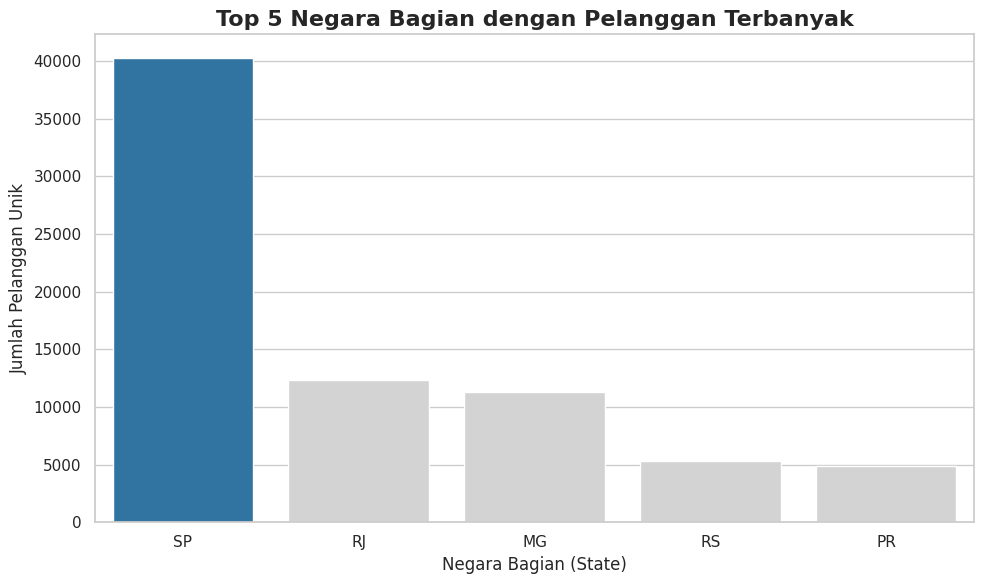

In [7]:
plt.figure(figsize=(10, 6))
colors = ["#1f77b4" if i == 0 else "#d3d3d3" for i in range(5)]

sns.barplot(
    x='customer_state',
    y='customer_count',
    hue='customer_state',
    data=top_states.head(5),
    palette=colors,
    legend=False
)

plt.title("Top 5 Negara Bagian dengan Pelanggan Terbanyak", fontsize=16, fontweight='bold')
plt.xlabel("Negara Bagian (State)", fontsize=12)
plt.ylabel("Jumlah Pelanggan Unik", fontsize=12)
plt.tight_layout()
plt.show()

**Insight:**
- Terlihat dari diagram bar bahwa baik dari level Kota maupun Negara Bagian, **São Paulo (SP)** sangat mendominasi ekosistem E-Commerce ini. Jaraknya dengan urutan kedua sangat signifikan.

## Segmentasi Geografis (Agregasi Wilayah Makro)

,region_cluster,customer_count,percentage (%)
0,Sudeste,65890,68.57
1,Sul,13688,14.24
2,Nordeste,9133,9.50
3,Centro-Oeste,5592,5.82
4,Norte,1793,1.87


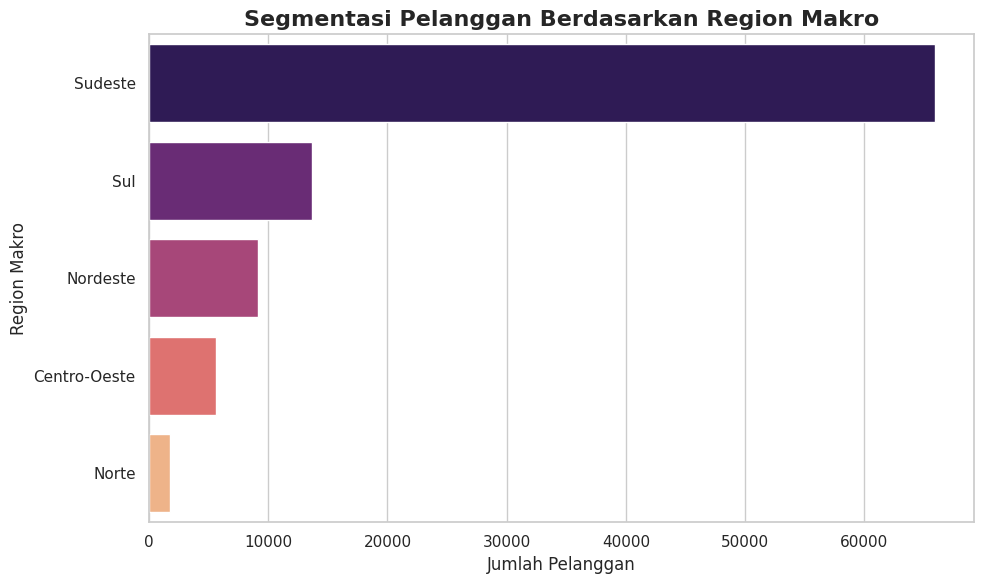

In [8]:
brazil_regions = {
    'AM': 'Norte', 'RR': 'Norte', 'AP': 'Norte', 'PA': 'Norte', 'TO': 'Norte', 'RO': 'Norte', 'AC': 'Norte',
    'MA': 'Nordeste', 'PI': 'Nordeste', 'CE': 'Nordeste', 'RN': 'Nordeste', 'PE': 'Nordeste', 'PB': 'Nordeste', 'SE': 'Nordeste', 'AL': 'Nordeste', 'BA': 'Nordeste',
    'MT': 'Centro-Oeste', 'MS': 'Centro-Oeste', 'GO': 'Centro-Oeste', 'DF': 'Centro-Oeste',
    'SP': 'Sudeste', 'RJ': 'Sudeste', 'ES': 'Sudeste', 'MG': 'Sudeste',
    'PR': 'Sul', 'RS': 'Sul', 'SC': 'Sul'
}

customers_df['region_cluster'] = customers_df['customer_state'].map(brazil_regions)

region_counts = customers_df.groupby('region_cluster').customer_unique_id.nunique().sort_values(ascending=False).reset_index()
region_counts.rename(columns={'customer_unique_id': 'customer_count'}, inplace=True)
region_counts['percentage (%)'] = round((region_counts['customer_count'] / total_customers) * 100, 2)

display(region_counts)

plt.figure(figsize=(10, 6))
sns.barplot(
    x='customer_count',
    y='region_cluster',
    hue='region_cluster',
    data=region_counts,
    palette='magma',
    legend=False
)
plt.title('Segmentasi Pelanggan Berdasarkan Region Makro', fontsize=16, fontweight='bold')
plt.xlabel('Jumlah Pelanggan')
plt.ylabel('Region Makro')
plt.tight_layout()
plt.show()

## Conclusion & Recommendation

**Kesimpulan:**
- **Conclusion Pertanyaan 1:** Kota **São Paulo** menempati urutan pertama dengan konsentrasi pelanggan terbesar yaitu 14.971 pelanggan unik (15,58%), disusul oleh Rio de Janeiro dengan 6.611 pelanggan (6,88%), dan Belo Horizonte dengan 2.671 pelanggan (2,78%). Tujuh kota lainnya dalam Top 10 adalah Brasília (2,15%), Curitiba (1,52%), Campinas (1,45%), Porto Alegre (1,38%), Salvador (1,26%), Guarulhos (1,20%), dan São Bernardo do Campo (0,94%). Daftar ini memberikan gambaran konkret bahwa dominasi berpusat pada kota-kota metropolitan besar.
- **Conclusion Pertanyaan 2:** Distribusi pelanggan di 5 negara bagian teratas didominasi secara absolut oleh **SP (São Paulo)** dengan 40.295 pelanggan unik yang menyumbang 41,93% dari total pangsa pasar. Posisi selanjutnya diikuti oleh RJ (Rio de Janeiro) sebesar 12,88%, MG (Minas Gerais) sebesar 11,71%, RS (Rio Grande do Sul) sebesar 5,49%, dan PR (Paraná) sebesar 5,08%. Perbandingan ini menunjukkan ketimpangan yang sangat tinggi antara state SP dengan state lainnya.
- **Conclusion Analisis Lanjutan (Segmentasi Geografis):** Melalui segmentasi manual secara makro, terbukti bahwa region **Sudeste (Tenggara)** mendominasi penuh dengan menyumbang 68,57% dari total pelanggan keseluruhan (65.890 pelanggan unik), menjadikan wilayah ini sebagai motor penggerak utama bisnis.

**Rekomendasi Action Item:**
1. **Prioritas Infrastruktur Logistik:** Tim logistik diwajibkan untuk memprioritaskan penyelesaian pembangunan *hub* distribusi utama di **São Paulo** dan **Rio de Janeiro** pada kuartal depan, karena penggabungan kedua kota ini memegang persentase konsentrasi pasar terbesar. Hal ini akan memotong jarak tempuh logistik secara masif.
2. **Efisiensi Budget Marketing & CAC:** Tim marketing harus mengalokasikan minimal 68,57% (sesuai proporsi region Sudeste) dari *budget* kampanye promosi dan subsidi ongkir tahun ini ke negara bagian SP, RJ, dan MG. Mengingat konsentrasi di sana sangat padat, Customer Acquisition Cost (CAC) akan jauh lebih murah dan *conversion rate* akan lebih optimal dibandingkan memaksakan *ads* di wilayah dengan populasi pelanggan rendah.

In [9]:
customers_df.to_csv("clean_customers.csv", index=False)
print("Sukses! File clean_customers.csv berhasil dibuat dan siap diunduh untuk Dashboard.")

Sukses! File clean_customers.csv berhasil dibuat dan siap diunduh untuk Dashboard.
